# Dallas 311 — Exploratory Data Analysis

**Question:** When someone files a 311 request in Dallas, can we predict right away whether the city will miss its promised deadline?

This notebook explores the 2025 data before modeling. It answers five questions:
1. Which departments and request types miss deadlines most?
2. Do some council districts wait longer than others for the same type of request?
3. Does it matter how the request came in?
4. Are there seasonal, weekday or time-of-day patterns?
5. How long do requests actually take compared with the time the city promised?

## Setup

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.prep import load_data

pd.set_option("display.width", 200)

BLUE, RED, GRAY = "#3a6ea5", "#c0392b", "#9aa5b1"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
})

df = load_data()

# Requests with a due date: these are the ones a model can be trained on
dd = df[df["missed_deadline"].notna()].copy()
dd["missed_deadline"] = dd["missed_deadline"].astype(int)
OVERALL = dd["missed_deadline"].mean()

print(f"All requests: {len(df):,}")
print(f"With a due date: {len(dd):,}  |  missed: {dd['missed_deadline'].sum():,} ({OVERALL:.1%})")

All requests: 400,715
With a due date: 276,378  |  missed: 30,971 (11.2%)


`load_data()` (in `src/prep.py`) does the cleaning shared by every notebook:
- merges duplicate department names (*Sanitation Services → Sanitation*, *Dallas Water Utilities → Water Utilities*, *Transportation and Public Works → … Department*)
- adds `days_to_close`, `promised_days`, `missed_deadline`, `latitude`, `longitude`, and created month / weekday / hour
- drops 2 rows that closed before they were created

## 0. The target: how often are deadlines missed?

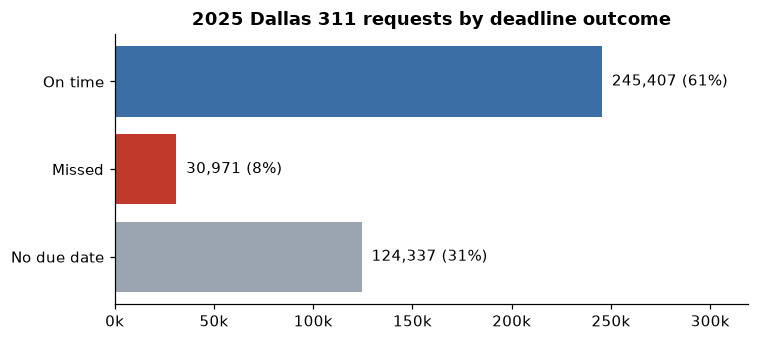

In [2]:
counts = pd.Series({
    "On time": (dd["missed_deadline"] == 0).sum(),
    "Missed": (dd["missed_deadline"] == 1).sum(),
    "No due date": df["missed_deadline"].isna().sum(),
})

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(counts.index[::-1], counts.values[::-1], color=[GRAY, RED, BLUE])
for b, v in zip(bars, counts.values[::-1]):
    ax.text(v, b.get_y() + b.get_height() / 2, f"  {v:,} ({v / len(df):.0%})", va="center")
ax.set_xlim(0, counts.max() * 1.3)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
ax.set_title("2025 Dallas 311 requests by deadline outcome")
plt.tight_layout()
plt.show()

Among requests with a due date, **about 11% miss it**: the classes are imbalanced. A model that always predicts "on time" would be about 89% accurate and completely useless, so accuracy alone can't be the metric. Almost all requests with no due date are **Code Concern – CCS**, which has no deadline; they're left out of the model.

## 1. Which departments and request types miss deadlines most?

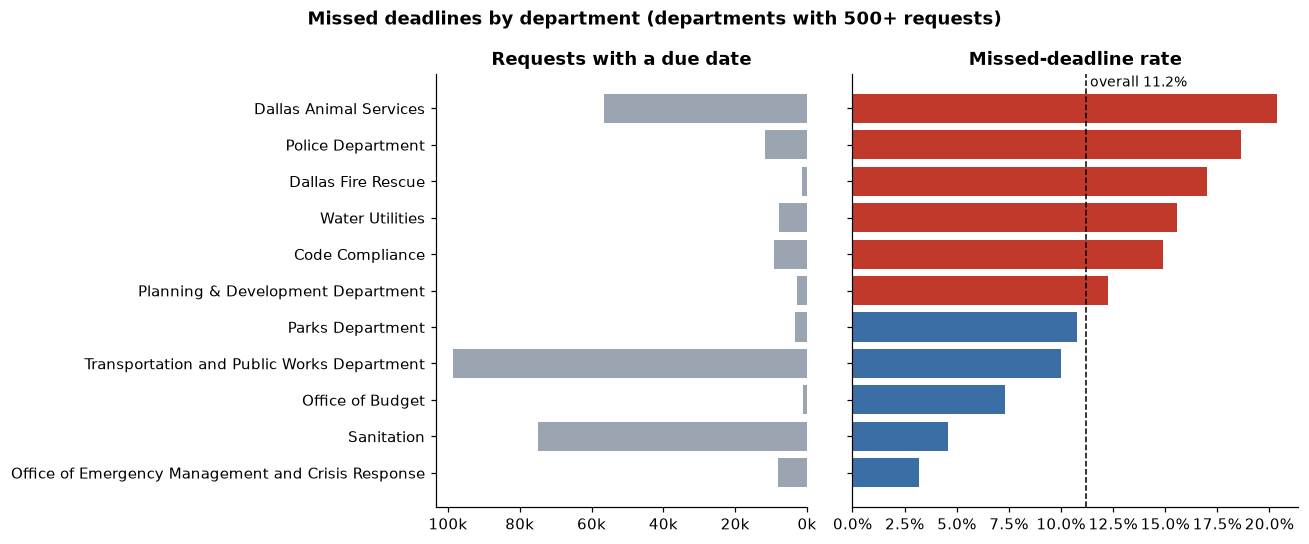

In [3]:
dept = (
    dd.groupby("department")["missed_deadline"]
    .agg(requests="size", missed_rate="mean")
    .query("requests >= 500")
    .sort_values("missed_rate")
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True,
                               gridspec_kw={"width_ratios": [1, 1.2]})
ax1.barh(dept.index, dept["requests"], color=GRAY)
ax1.set_title("Requests with a due date")
ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
ax1.invert_xaxis()

colors = [RED if r > OVERALL else BLUE for r in dept["missed_rate"]]
ax2.barh(dept.index, dept["missed_rate"], color=colors)
ax2.axvline(OVERALL, color="black", linestyle="--", linewidth=1)
ax2.text(OVERALL, len(dept) - 0.4, f" overall {OVERALL:.1%}", fontsize=9)
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set_title("Missed-deadline rate")
fig.suptitle("Missed deadlines by department (departments with 500+ requests)", fontweight="bold")
plt.tight_layout()
plt.show()

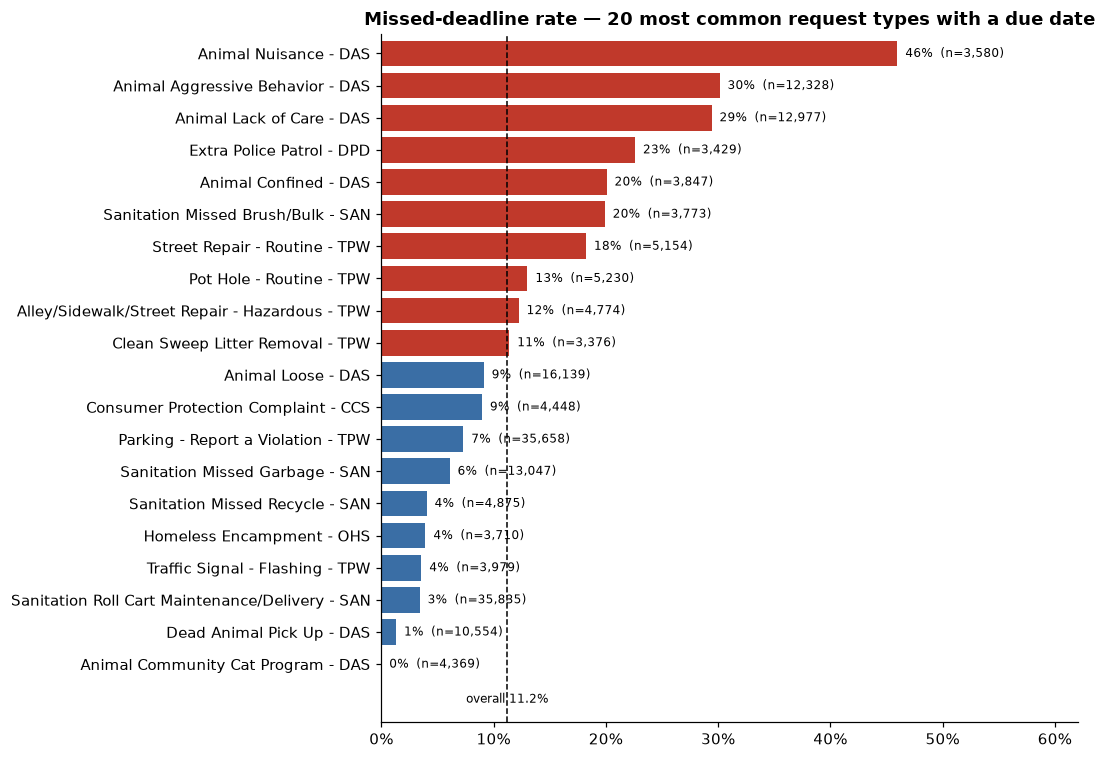

In [4]:
types = (
    dd.groupby("service_request_type")["missed_deadline"]
    .agg(requests="size", missed_rate="mean")
)
top = types.sort_values("requests", ascending=False).head(20).sort_values("missed_rate")

fig, ax = plt.subplots(figsize=(10, 7))
colors = [RED if r > OVERALL else BLUE for r in top["missed_rate"]]
ax.barh(top.index, top["missed_rate"], color=colors)
for i, (r, n) in enumerate(zip(top["missed_rate"], top["requests"])):
    ax.text(r, i, f"  {r:.0%}  (n={n:,})", va="center", fontsize=8)
ax.axvline(OVERALL, color="black", linestyle="--", linewidth=1)
ax.text(OVERALL, -1.2, f"overall {OVERALL:.1%}", ha="center", fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, top["missed_rate"].max() * 1.35)
ax.set_ylim(-1.8, len(top) - 0.4)
ax.set_title("Missed-deadline rate — 20 most common request types with a due date")
plt.tight_layout()
plt.show()

**Findings:**
- **Dallas Animal Services** misses most often, driven by Animal Nuisance, Aggressive Behavior and Lack of Care. In the same department, Dead Animal Pick Up almost never misses.
- High-volume Sanitation requests (roll carts, missed garbage) rarely miss.
- Request type is likely to be the single strongest predictor.

## 2. Do some council districts wait longer for the same request?

Districts get different mixes of requests, so raw missed rates can mislead. To compare fairly, each request gets an **expected** miss probability: the citywide missed rate for its request type. A district's **ratio = actual missed rate ÷ expected missed rate**.
- 1.0 = the district does exactly as well as its request mix predicts
- above 1.0 = it misses more often than its request mix explains

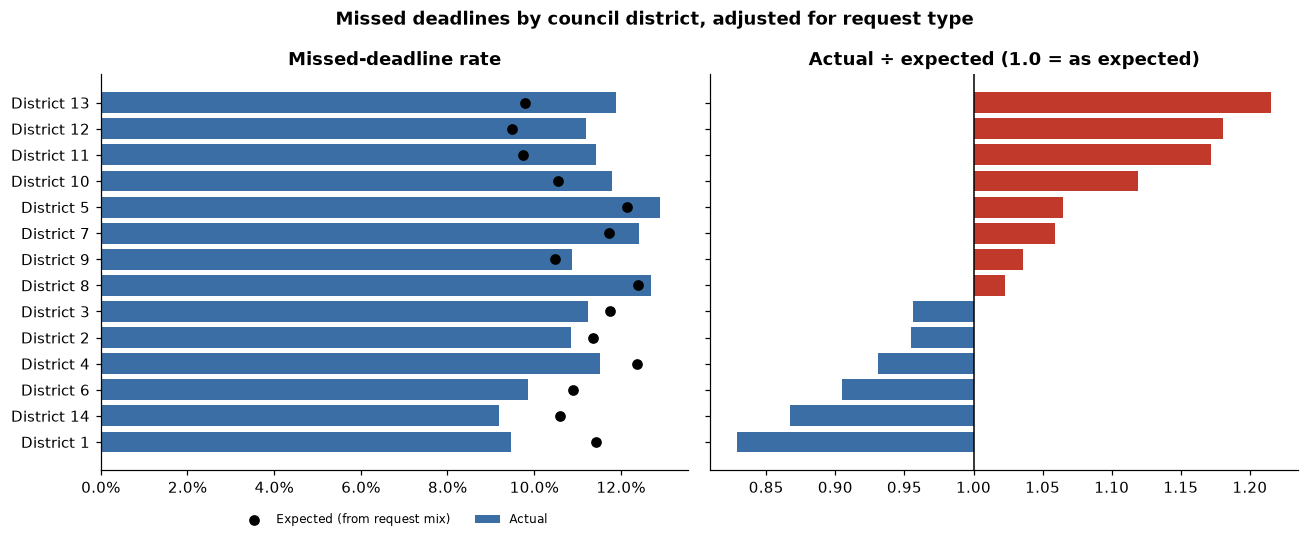

,requests,actual,expected,ratio
city_council_district,,,,
1,21696,0.095,0.114,0.829
14,23236,0.092,0.106,0.867
6,23200,0.099,0.109,0.905
4,26754,0.115,0.124,0.931
2,24782,0.109,0.114,0.955
3,17610,0.112,0.117,0.956
8,21775,0.127,0.124,1.023
9,17792,0.109,0.105,1.036
7,23507,0.124,0.117,1.059


In [5]:
dd["expected"] = dd.groupby("service_request_type")["missed_deadline"].transform("mean")

dist = (
    dd.dropna(subset=["city_council_district"])
    .groupby("city_council_district")
    .agg(requests=("missed_deadline", "size"),
         actual=("missed_deadline", "mean"),
         expected=("expected", "mean"))
)
dist["ratio"] = dist["actual"] / dist["expected"]
dist = dist.sort_values("ratio")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
labels = [f"District {d}" for d in dist.index]

ax1.barh(labels, dist["actual"], color=BLUE, label="Actual")
ax1.scatter(dist["expected"], labels, color="black", zorder=3, label="Expected (from request mix)")
ax1.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax1.set_title("Missed-deadline rate")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=8, frameon=False)

colors = [RED if r > 1 else BLUE for r in dist["ratio"]]
ax2.barh(labels, dist["ratio"] - 1, left=1, color=colors)
ax2.axvline(1, color="black", linewidth=1)
ax2.set_title("Actual ÷ expected (1.0 = as expected)")
fig.suptitle("Missed deadlines by council district, adjusted for request type", fontweight="bold")
plt.tight_layout()
plt.show()

dist.round(3)

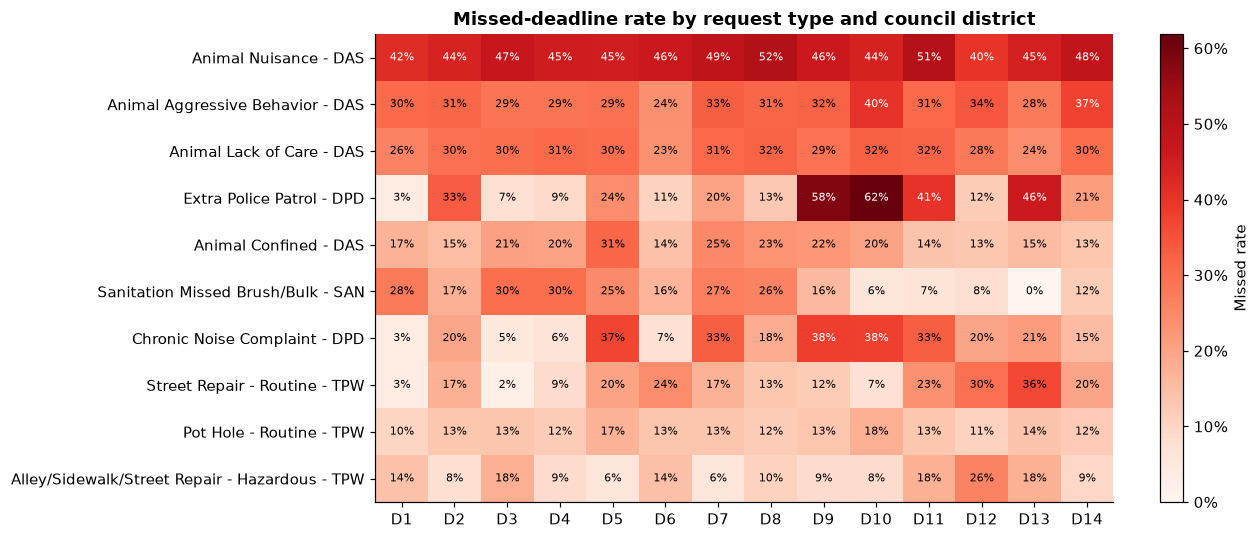

In [6]:
top_types = types.query("requests >= 3000").sort_values("missed_rate", ascending=False).index[:10]
heat = (
    dd[dd["service_request_type"].isin(top_types)]
    .pivot_table(index="service_request_type", columns="city_council_district",
                 values="missed_deadline", aggfunc="mean")
    .loc[top_types]
)

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(heat.values, cmap="Reds", aspect="auto", vmin=0)
ax.set_xticks(range(heat.shape[1]), [f"D{int(c)}" for c in heat.columns])
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if v > heat.values[~np.isnan(heat.values)].max() * 0.6 else "black")
fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0), label="Missed rate")
ax.set_title("Missed-deadline rate by request type and council district")
plt.tight_layout()
plt.show()

**Findings:**
- After adjusting for request type, **Districts 13, 12, 11 and 10 miss 12–22% more often than expected**, while **Districts 1, 14 and 6 miss 10–17% less often**.
- The gaps are biggest for police requests: **Extra Police Patrol** misses 3% of the time in District 1 but 58–62% in Districts 9 and 10. **Chronic Noise Complaint** shows a similar spread.
- Animal Services requests miss at high rates in *every* district, so that problem is citywide, not local.

**Use for the ethics slide:** if some districts consistently miss more than their request mix predicts, residents there get slower service for the same problems. A prediction model could also make this worse if the city used it to deprioritize "likely late" requests, since those cluster in certain districts. Whatever model is built should be checked district by district.

## 3. Does it matter how the request came in?

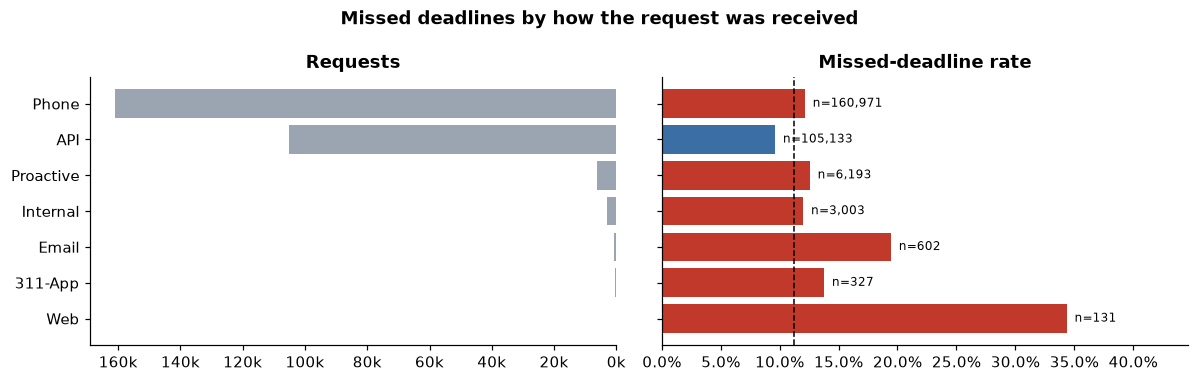

In [7]:
method = (
    dd.groupby("method_received_description")["missed_deadline"]
    .agg(requests="size", missed_rate="mean")
    .query("requests >= 100")
    .sort_values("requests")
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
ax1.barh(method.index, method["requests"], color=GRAY)
ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
ax1.set_title("Requests")
ax1.invert_xaxis()
colors = [RED if r > OVERALL else BLUE for r in method["missed_rate"]]
ax2.barh(method.index, method["missed_rate"], color=colors)
for i, (r, n) in enumerate(zip(method["missed_rate"], method["requests"])):
    ax2.text(r, i, f"  n={n:,}", va="center", fontsize=8)
ax2.axvline(OVERALL, color="black", linestyle="--", linewidth=1)
ax2.set_xlim(0, method["missed_rate"].max() * 1.3)
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set_title("Missed-deadline rate")
fig.suptitle("Missed deadlines by how the request was received", fontweight="bold")
plt.tight_layout()
plt.show()

Phone and API account for almost all requests. *Proactive* means city staff spotted the problem themselves. Email, 311-App and Web have only a few hundred requests each, so their high rates are less reliable. Differences here may reflect the kinds of requests each channel handles, not the channel itself.

## 4. Time patterns

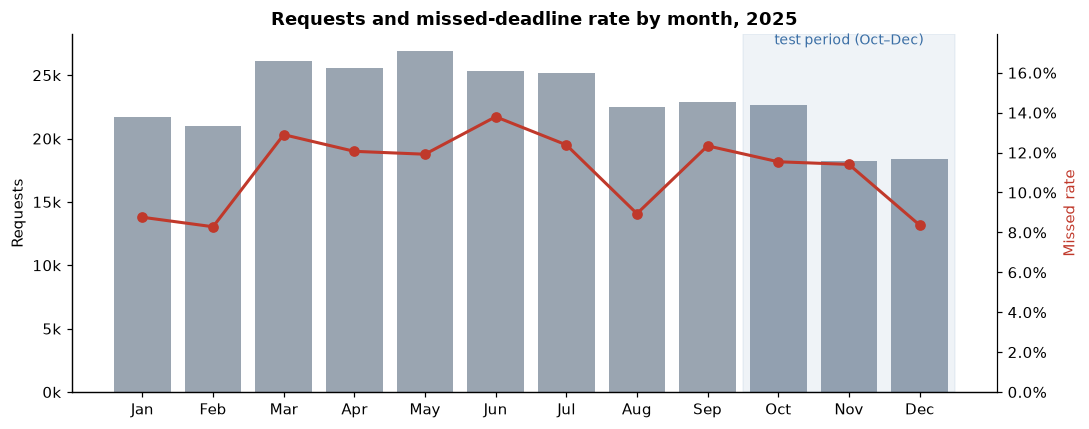

In [8]:
monthly = dd.groupby("created_month")["missed_deadline"].agg(requests="size", missed_rate="mean")
month_names = pd.to_datetime(monthly.index.astype(str), format="%m").strftime("%b")

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(month_names, monthly["requests"], color=GRAY, label="Requests")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
ax1.set_ylabel("Requests")
ax2 = ax1.twinx()
ax2.plot(month_names, monthly["missed_rate"], color=RED, marker="o", linewidth=2, label="Missed rate")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set_ylim(0, monthly["missed_rate"].max() * 1.3)
ax2.set_ylabel("Missed rate", color=RED)
ax2.spines["right"].set_visible(True)
ax1.axvspan(8.5, 11.5, color=BLUE, alpha=0.08)
ax1.text(10, monthly["requests"].max() * 1.02, "test period (Oct–Dec)", ha="center", fontsize=9, color=BLUE)
ax1.set_title("Requests and missed-deadline rate by month, 2025")
plt.tight_layout()
plt.show()

The shaded months are the planned **test set**: the model will train on Jan–Sep and be tested on Oct–Dec, to mimic predicting the future. Any shift between the two periods is **data drift** and should be discussed.

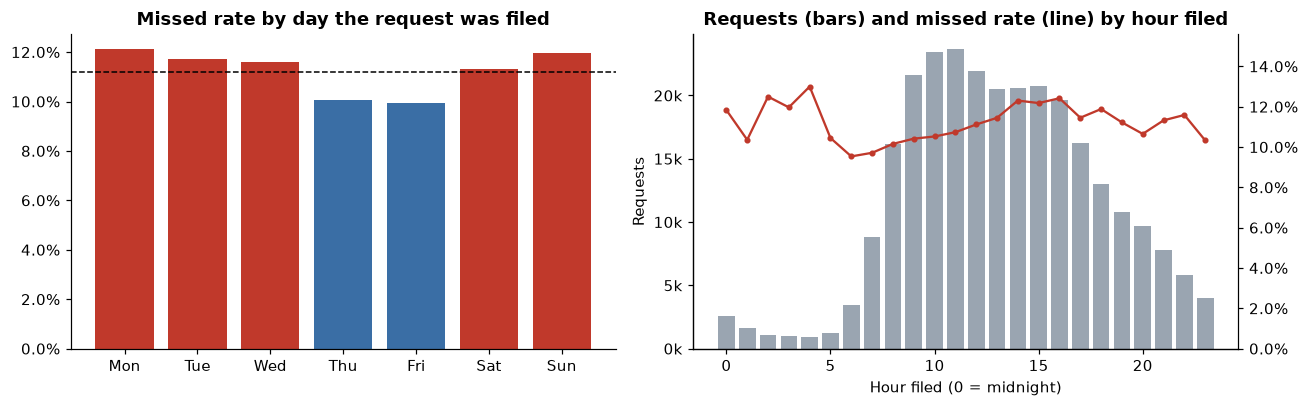

In [9]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = dd.groupby("created_weekday")["missed_deadline"].agg(requests="size", missed_rate="mean").loc[order]
hr = dd.groupby("created_hour")["missed_deadline"].agg(requests="size", missed_rate="mean")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
colors = [RED if r > OVERALL else BLUE for r in wd["missed_rate"]]
ax1.bar([d[:3] for d in order], wd["missed_rate"], color=colors)
ax1.axhline(OVERALL, color="black", linestyle="--", linewidth=1)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax1.set_title("Missed rate by day the request was filed")

ax2.bar(hr.index, hr["requests"], color=GRAY)
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
ax2.set_xlabel("Hour filed (0 = midnight)")
ax2.set_ylabel("Requests")
ax3 = ax2.twinx()
ax3.plot(hr.index, hr["missed_rate"], color=RED, marker=".", linewidth=1.5)
ax3.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax3.set_ylim(0, hr["missed_rate"].max() * 1.2)
ax3.spines["right"].set_visible(True)
ax2.set_title("Requests (bars) and missed rate (line) by hour filed")
plt.tight_layout()
plt.show()

**Findings:**
- Missed rates are lowest in **Jan–Feb, Aug and Dec** (8–9%) and highest in **Mar and Jun** (13–14%). Request volume also peaks in spring and early summer.
- The test months (Oct–Dec) average about the same as the training months, so drift looks mild, though December drops noticeably.
- Requests filed **Thursday and Friday** miss less often (about 10%) than requests filed on other days (about 12%).
- Time of day has only a small effect.

## 5. Actual time to close vs. the time the city promised

`promised_days` = due date − created date. Points **above the diagonal** took longer than promised on a typical (median) request.

C:\Users\Mateen Jan\AppData\Local\Temp\ipykernel_5704\1568599750.py:20: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(lo, hi)
C:\Users\Mateen Jan\AppData\Local\Temp\ipykernel_5704\1568599750.py:21: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(lo, hi)


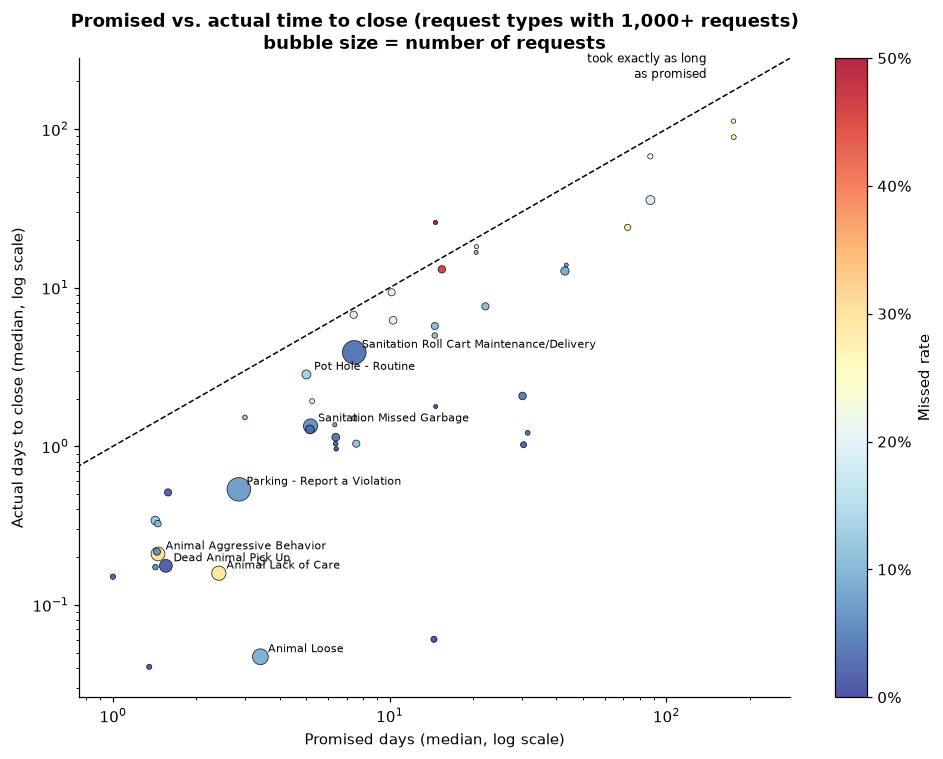

In [10]:
comp = (
    dd.groupby("service_request_type")
    .agg(requests=("missed_deadline", "size"),
         promised=("promised_days", "median"),
         actual=("days_to_close", "median"),
         missed_rate=("missed_deadline", "mean"))
    .query("requests >= 1000")
)

fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(comp["promised"], comp["actual"], s=comp["requests"] / 150,
                c=comp["missed_rate"], cmap="RdYlBu_r", vmin=0, vmax=0.5,
                edgecolor="black", linewidth=0.5, alpha=0.85)
lo = min(comp["promised"].min(), comp["actual"].min()) * 0.6
hi = max(comp["promised"].max(), comp["actual"].max()) * 1.6
ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=1)
ax.text(hi * 0.5, hi * 0.75, "took exactly as long\nas promised", fontsize=8, ha="right")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_xlabel("Promised days (median, log scale)")
ax.set_ylabel("Actual days to close (median, log scale)")
for name, row in comp.sort_values("requests", ascending=False).head(8).iterrows():
    ax.annotate(name.rsplit(" - ", 1)[0], (row["promised"], row["actual"]), fontsize=7,
                xytext=(5, 3), textcoords="offset points")
fig.colorbar(sc, ax=ax, format=mtick.PercentFormatter(1.0), label="Missed rate")
ax.set_title("Promised vs. actual time to close (request types with 1,000+ requests)\nbubble size = number of requests")
plt.tight_layout()
plt.show()

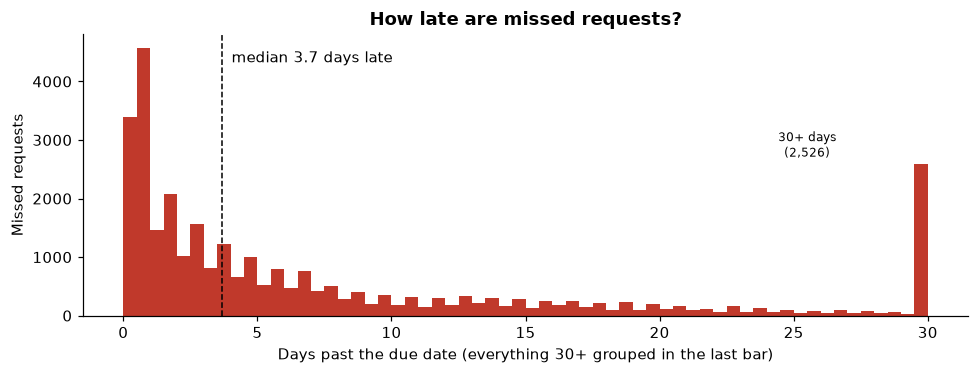

Missed by under 1 day: 26%  |  more than 7 days: 34%


In [11]:
late = dd[dd["missed_deadline"] == 1]
days_late = (late["closed_date"] - late["overall_service_request_due_date"]).dt.total_seconds() / 86400

fig, ax = plt.subplots(figsize=(9, 3.5))
counts_, _, _ = ax.hist(days_late.clip(upper=30), bins=60, color=RED)
ax.axvline(days_late.median(), color="black", linestyle="--", linewidth=1)
ax.text(days_late.median(), ax.get_ylim()[1] * 0.9, f"  median {days_late.median():.1f} days late")
ax.annotate(f"30+ days\n({(days_late >= 30).sum():,})", (30, counts_[-1]), xytext=(25.5, counts_[-1] * 1.05),
            fontsize=8, ha="center")
ax.set_xlabel("Days past the due date (everything 30+ grouped in the last bar)")
ax.set_ylabel("Missed requests")
ax.set_title("How late are missed requests?")
plt.tight_layout()
plt.show()

print(f"Missed by under 1 day: {(days_late < 1).mean():.0%}  |  more than 7 days: {(days_late > 7).mean():.0%}")

**Findings:**
- Almost every request type sits **below the diagonal**: the *typical* request closes well before its deadline. Missed deadlines are the long tail, not the norm. Animal Aggressive Behavior, for example, usually closes within hours, yet 30% still miss.
- Misses split into two groups: about a quarter are less than a day late (near misses), while about a third are more than a week late (requests that got stuck). That distinction is worth mentioning when interpreting the model.

## 6. Where are deadlines missed? (map)

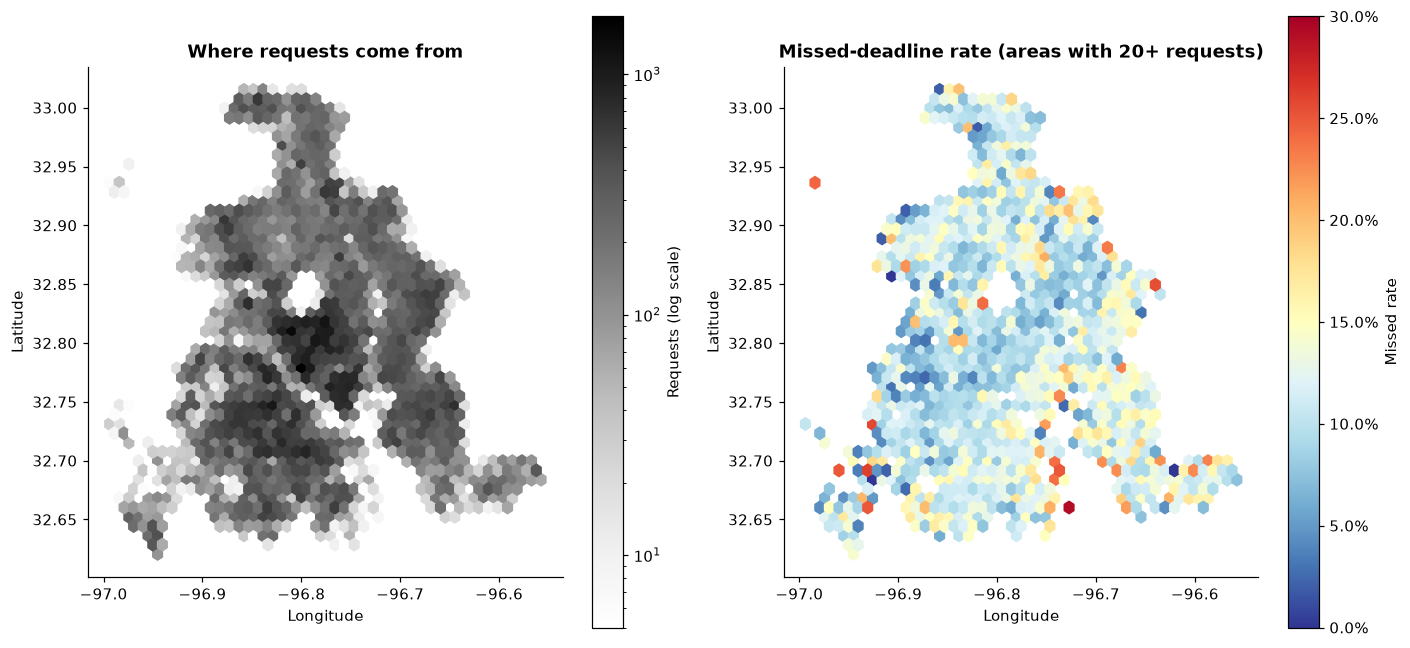

In [12]:
geo = dd.dropna(subset=["latitude", "longitude"])
geo = geo[geo["latitude"].between(32.6, 33.05) & geo["longitude"].between(-97.0, -96.55)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
hb1 = ax1.hexbin(geo["longitude"], geo["latitude"], gridsize=45, cmap="Greys", mincnt=5, bins="log")
fig.colorbar(hb1, ax=ax1, label="Requests (log scale)")
ax1.set_title("Where requests come from")

hb2 = ax2.hexbin(geo["longitude"], geo["latitude"], C=geo["missed_deadline"], reduce_C_function=np.mean,
                 gridsize=45, cmap="RdYlBu_r", mincnt=20, vmin=0, vmax=0.3)
fig.colorbar(hb2, ax=ax2, format=mtick.PercentFormatter(1.0), label="Missed rate")
ax2.set_title("Missed-deadline rate (areas with 20+ requests)")

for ax in (ax1, ax2):
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect(1 / np.cos(np.radians(32.8)))
plt.tight_layout()
plt.show()

## Summary for the modeling notebook

- **Target:** `missed_deadline`, about 11% positive → use class weights or SMOTE, and judge models by recall, precision, F1, balanced accuracy and PR-AUC, not accuracy.
- **Model data:** requests with a due date only (Code Concern excluded).
- **Strong candidate features:** request type, department, promised time (ERT), priority, intake method, council district, created month/weekday/hour, location.
- **Leakage to exclude:** `closed_date`, `days_to_close`, `outcome`, `status`; all are only known after the request is done.
- **Split:** train on Jan–Sep, test on Oct–Dec 2025, and check for drift.
- **Fairness:** compare model errors across council districts.